In [16]:
import pandas as pd

In [17]:
data = pd.read_csv("/content/student_exam_performance.csv")
backup_data = data.copy()
data.sample(5)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
16106,STU_016107,18,Male,High School,Public,Lower-Middle,Master,Urban,61.55,2.27,...,Easy,15,100,48,63.94,8.53,44.60,F,Fail,Low
72493,STU_072494,15,Male,High School,Public,Low,Bachelor,Urban,65.30,2.84,...,Medium,18,94,45,88.74,8.86,46.16,F,Fail,Low
49327,STU_049328,18,Female,High School,Private,Middle,Master,Suburban,79.90,3.35,...,Easy,12,100,73,63.05,8.89,73.17,C,Pass,Medium
60794,STU_060795,15,Male,Undergraduate,Public,Low,Bachelor,Suburban,52.81,1.91,...,Hard,17,93,59,81.85,8.35,65.71,C,Pass,Medium
82430,STU_082431,16,Male,High School,Public,Lower-Middle,High School,Urban,70.92,2.62,...,Medium,17,96,73,100.00,7.19,76.52,B,Pass,Medium


In [18]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

In [19]:
target = 'exam_score'
exclude_cols = ['student_id','exam_score','performance_grade','pass_status','performance_level']

inputFeature = pd.DataFrame(data.drop(columns=[target]+exclude_cols))
targetFeature = pd.DataFrame(data[target])

inputFeature.shape, targetFeature.shape

((100000, 39), (100000, 1))

In [20]:
inputFeature.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,5.000495,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,1.775716,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,1.000000,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,3.770000,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,4.990000,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,6.210000,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.080000,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000


In [21]:
print(inputFeature.isnull().sum()/100)

age                            0.00
gender                         0.00
education_level                0.00
school_type                    0.00
family_income                  0.00
parent_education              65.26
urban_rural                    0.00
previous_exam_score            0.00
previous_gpa                  77.93
attendance_percentage         98.63
assignment_completion_rate     0.00
class_participation            0.00
study_hours_per_day            0.00
self_study_hours               0.00
private_tuition                0.00
online_learning_hours          0.00
study_consistency              0.00
study_environment              0.00
study_method                   0.00
revision_frequency             0.00
practice_tests_completed       0.00
notes_quality                 84.07
sleep_hours                    0.00
sleep_quality                 69.94
daily_screen_time              0.00
physical_activity_hours        0.00
break_frequency                0.00
stress_level                

In [22]:
targetFeature.isnull().sum()

,0
exam_score,0


In [23]:
import matplotlib.pyplot as plt
fig = plt.gcf()
fig.set_size_inches(8, 8)
import seaborn as sns

<Figure size 800x800 with 0 Axes>

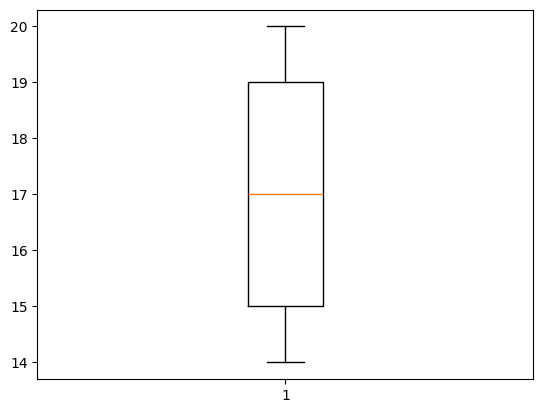

In [24]:
plt.boxplot(inputFeature['age'])
plt.show()

In [25]:
# missing values fill categorical and numerical coloums
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="most_frequent")
inputFeature = pd.DataFrame(imputer.fit_transform(inputFeature), columns=inputFeature.columns)
# inputFeature.isnull().sum()

In [26]:
# import pandas as pd

# inputFeature.to_csv('student_data.csv', index=False)

In [27]:
inputFeature

,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,...,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level
0,20,Female,High School,Public,Middle,High School,Rural,78.36,2.95,81.49,...,1,Shared,Low,2.15,Medium,27,95,86,100.0,9.39
1,17,Male,High School,Public,Middle,High School,Suburban,73.4,2.89,100.0,...,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31
2,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.0,...,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87
3,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,...,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68
4,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,...,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,17,Male,Undergraduate,Public,Upper-Middle,High School,Suburban,78.73,2.78,89.67,...,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36
99996,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.7,2.98,83.87,...,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68
99997,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,...,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97
99998,15,Female,High School,Private,High,Master,Rural,74.7,3.06,92.61,...,1,Shared,Moderate,0.55,Medium,28,93,81,100.0,10.0


In [32]:
from sklearn.preprocessing import LabelEncoder

# List of columns to encode
categorical_cols = ["gender", "education_level",
                    "school_type", "family_income",
                    "parent_education", "urban_rural",
                    "device_availability","educational_app_usage",
                    "exam_difficulty"]

# Apply LabelEncoder column by column
for col in categorical_cols:
    le = LabelEncoder()
    inputFeature[col] = le.fit_transform(inputFeature[col])

inputFeature

,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,...,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level
0,20,0,0,2,3,3,0,78.36,2.95,81.49,...,1,1,1,2.15,2,27,95,86,100.0,9.39
1,17,1,0,2,3,3,1,73.4,2.89,100.0,...,1,1,2,4.37,0,4,100,86,87.17,6.31
2,18,2,1,2,3,4,2,82.76,3.35,100.0,...,1,0,1,1.43,0,28,96,74,63.77,9.87
3,20,1,0,2,3,3,1,60.61,2.57,84.91,...,1,0,1,3.69,2,16,97,77,59.51,9.68
4,16,0,0,1,0,1,1,74.79,2.84,88.21,...,1,0,2,1.97,2,28,98,52,84.64,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,17,1,1,2,4,3,1,78.73,2.78,89.67,...,1,1,0,6.43,2,5,95,62,76.13,8.36
99996,14,0,0,2,4,1,1,75.7,2.98,83.87,...,1,0,1,4.34,0,24,94,91,84.29,8.68
99997,16,0,0,2,4,3,1,84.69,3.27,89.57,...,1,0,2,11.91,2,24,85,65,62.32,9.97
99998,15,0,0,1,0,4,0,74.7,3.06,92.61,...,1,1,2,0.55,2,28,93,81,100.0,10.0


In [41]:
inputFeature.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 39 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   age                         100000 non-null  object
 1   gender                      100000 non-null  int64 
 2   education_level             100000 non-null  int64 
 3   school_type                 100000 non-null  int64 
 4   family_income               100000 non-null  int64 
 5   parent_education            100000 non-null  int64 
 6   urban_rural                 100000 non-null  int64 
 7   previous_exam_score         100000 non-null  object
 8   previous_gpa                100000 non-null  object
 9   attendance_percentage       100000 non-null  object
 10  assignment_completion_rate  100000 non-null  object
 11  class_participation         100000 non-null  object
 12  study_hours_per_day         100000 non-null  object
 13  self_study_hours            10

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Ensure all numeric values are represented properly
for col in inputFeature.columns:
    # Try to convert to numeric, if not possible (contains actual text), keep as object
    converted = pd.to_numeric(inputFeature[col], errors='ignore')
    inputFeature[col] = converted

# Encode any remaining categorical (object) columns
le = LabelEncoder()
for col in inputFeature.select_dtypes(include=['object']).columns:
    inputFeature[col] = le.fit_transform(inputFeature[col].astype(str))

# Ensure targetFeature is numeric
targetFeature = targetFeature.apply(pd.to_numeric)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(inputFeature, targetFeature, test_size=0.2, random_state=42)

# Fit the model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

Mean Squared Error: 3.2254933807835022
R-squared: 0.9870246633276868


/tmp/ipykernel_8658/3572977574.py:10: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  converted = pd.to_numeric(inputFeature[col], errors='ignore')


In [37]:
X_train

,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,...,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level
75220,15,0,0,0,3,1,2,53.74,2.31,87.84,...,1,0,2,6.47,1,1,87,13,100.0,9.65
48955,18,0,0,2,1,3,0,44.64,1.78,100.0,...,1,1,0,1.1,0,25,92,51,52.79,10.0
44966,16,1,0,2,2,1,2,74.54,2.78,89.25,...,1,0,2,3.3,2,16,86,60,100.0,10.0
13568,20,0,0,1,3,1,2,46.71,1.93,74.96,...,1,0,1,5.64,2,12,92,47,82.98,8.07
92727,14,0,0,2,4,2,2,77.18,3.17,95.79,...,1,0,2,0.41,0,21,91,48,74.05,9.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6265,18,0,0,0,4,2,2,62.69,2.62,90.55,...,1,0,2,5.66,2,4,98,37,84.28,10.0
54886,19,1,0,1,3,0,2,84.41,3.22,88.38,...,1,0,1,15.96,1,24,90,49,100.0,10.0
76820,20,0,1,2,2,0,1,75.55,3.08,100.0,...,0,1,2,3.89,0,12,85,81,68.15,9.33
860,17,0,1,0,2,3,2,57.82,2.78,83.43,...,1,0,2,2.9,2,20,89,61,94.36,9.89


In [38]:
y_train

,exam_score
75220,16.04
48955,54.57
44966,70.06
13568,53.31
92727,50.30
...,...
6265,38.16
54886,56.76
76820,94.23
860,69.37


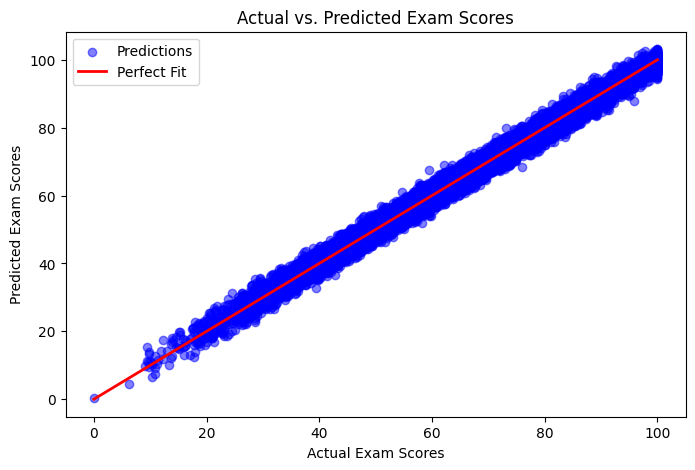

In [51]:
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5, label='Predictions')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Perfect Fit')

plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')
plt.title('Actual vs. Predicted Exam Scores')
plt.legend()
plt.show()

In [56]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
x_train = pd.DataFrame(X_train_scaled, columns=X_train.columns)
x_test = pd.DataFrame(X_test_scaled, columns=X_test.columns)
x_train

model2 = LinearRegression()
model2.fit(x_train, y_train)

y_pred = model2.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")

Mean Squared Error: 3.225493380783502
R-squared: 0.9870246633276868
